# Eksperimen Sistem Machine Learning
**Nama Siswa:** Maulana Haekal Noval Akbar  
**Dataset:** Heart Disease Prediction Dataset (Kaggle: oktayrdeki/heart-disease)  
**Tujuan:** Membangun eksperimen eksplorasi data (EDA) dan pipeline preprocessing otomatis untuk mendeteksi risiko penyakit jantung (*Heart Disease Status*).  
*Template mengacu pada Template Eksperimen MSML Dicoding.*


## 1. Data Loading & Inspection
Memuat dataset mentah yang diunduh melalui Kaggle (heart_disease.csv) dari folder heart_disease_raw.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Memuat dataset mentah
df_raw = pd.read_csv('heart_disease_raw/heart_disease.csv')
print('Dimensi data:', df_raw.shape)
df_raw.head()


Dimensi data: (10000, 21)


,Age,Gender,Blood Pressure,Cholesterol Level,Exercise Habits,Smoking,Family Heart Disease,Diabetes,BMI,High Blood Pressure,...,High LDL Cholesterol,Alcohol Consumption,Stress Level,Sleep Hours,Sugar Consumption,Triglyceride Level,Fasting Blood Sugar,CRP Level,Homocysteine Level,Heart Disease Status
0,56.0,Male,153.0,155.0,High,Yes,Yes,No,24.991591,Yes,...,No,High,Medium,7.633228,Medium,342.0,NaN,12.969246,12.387250,No
1,69.0,Female,146.0,286.0,High,No,Yes,Yes,25.221799,No,...,No,Medium,High,8.744034,Medium,133.0,157.0,9.355389,19.298875,No
2,46.0,Male,126.0,216.0,Low,No,No,No,29.855447,No,...,Yes,Low,Low,4.440440,Low,393.0,92.0,12.709873,11.230926,No
3,32.0,Female,122.0,293.0,High,Yes,Yes,No,24.130477,Yes,...,Yes,Low,High,5.249405,High,293.0,94.0,12.509046,5.961958,No
4,60.0,Male,166.0,242.0,Low,Yes,Yes,Yes,20.486289,Yes,...,No,Low,High,7.030971,High,263.0,154.0,10.381259,8.153887,No


In [2]:
# Memeriksa tipe data dan kelengkapan kolom
df_raw.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 21 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Age                   9971 non-null   float64
 1   Gender                9981 non-null   object 
 2   Blood Pressure        9981 non-null   float64
 3   Cholesterol Level     9970 non-null   float64
 4   Exercise Habits       9975 non-null   object 
 5   Smoking               9975 non-null   object 
 6   Family Heart Disease  9979 non-null   object 
 7   Diabetes              9970 non-null   object 
 8   BMI                   9978 non-null   float64
 9   High Blood Pressure   9974 non-null   object 
 10  Low HDL Cholesterol   9975 non-null   object 
 11  High LDL Cholesterol  9974 non-null   object 
 12  Alcohol Consumption   7414 non-null   object 
 13  Stress Level          9978 non-null   object 
 14  Sleep Hours           9975 non-null   float64
 15  Sugar Consumption   

## 2. Exploratory Data Analysis (EDA)
Menganalisis ringkasan statistik, persentase nilai kosong (*missing values*), dan visualisasi distribusi target *Heart Disease Status*.


In [3]:
# Ringkasan statistik data numerik
df_raw.describe()


,Age,Blood Pressure,Cholesterol Level,BMI,Sleep Hours,Triglyceride Level,Fasting Blood Sugar,CRP Level,Homocysteine Level
count,9971.000000,9981.000000,9970.000000,9978.000000,9975.000000,9974.000000,9978.000000,9974.000000,9980.000000
mean,49.296259,149.757740,225.425577,29.077269,6.991329,250.734409,120.142213,7.472201,12.456271
std,18.193970,17.572969,43.575809,6.307098,1.753195,87.067226,23.584011,4.340248,4.323426
min,18.000000,120.000000,150.000000,18.002837,4.000605,100.000000,80.000000,0.003647,5.000236
25%,34.000000,134.000000,187.000000,23.658075,5.449866,176.000000,99.000000,3.674126,8.723334
50%,49.000000,150.000000,226.000000,29.079492,7.003252,250.000000,120.000000,7.472164,12.409395
75%,65.000000,165.000000,263.000000,34.520015,8.531577,326.000000,141.000000,11.255592,16.140564
max,80.000000,180.000000,300.000000,39.996954,9.999952,400.000000,160.000000,14.997087,19.999037


In [4]:
# Memeriksa missing values per kolom
missing_counts = df_raw.isnull().sum()
print('Jumlah missing value per kolom:')
print(missing_counts[missing_counts > 0])


Jumlah missing value per kolom:
Age                       29
Gender                    19
Blood Pressure            19
Cholesterol Level         30
Exercise Habits           25
Smoking                   25
Family Heart Disease      21
Diabetes                  30
BMI                       22
High Blood Pressure       26
Low HDL Cholesterol       25
High LDL Cholesterol      26
Alcohol Consumption     2586
Stress Level              22
Sleep Hours               25
Sugar Consumption         30
Triglyceride Level        26
Fasting Blood Sugar       22
CRP Level                 26
Homocysteine Level        20
dtype: int64


C:\Users\HP\AppData\Local\Temp\ipykernel_38212\3220778929.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='Heart Disease Status', data=df_raw, palette='Set2')


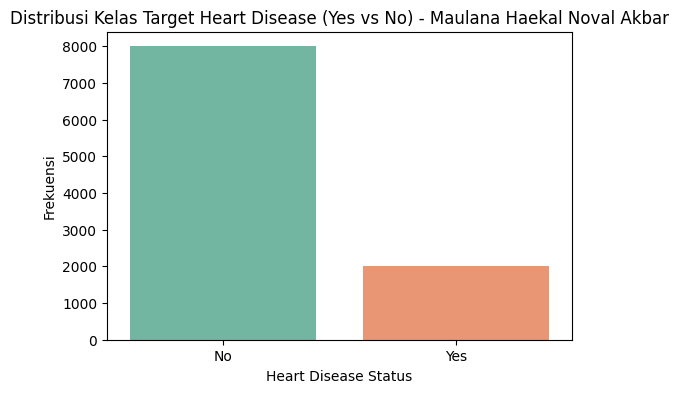

In [5]:
# Visualisasi distribusi target (Heart Disease Status)
plt.figure(figsize=(6, 4))
sns.countplot(x='Heart Disease Status', data=df_raw, palette='Set2')
plt.title('Distribusi Kelas Target Heart Disease (Yes vs No) - Maulana Haekal Noval Akbar')
plt.xlabel('Heart Disease Status')
plt.ylabel('Frekuensi')
plt.show()


## 3. Data Preprocessing
Tahap transformasi data:
1. Imputasi fitur numerik dengan nilai Median
2. Imputasi fitur kategorikal dengan nilai Modus (Mode)
3. Transformasi nama kolom agar konsisten
4. Encoding variabel kategorikal (One-Hot Encoding) & Target Biner (0 dan 1)
5. Pembagian data latih dan data uji (Train-Test Split 80:20 berstrata)
6. Standardisasi fitur numerik menggunakan StandardScaler


In [6]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

df_clean = df_raw.copy()
df_clean.columns = [c.strip().replace(' ', '_') for c in df_clean.columns]

target_col = 'Heart_Disease_Status'
feature_cols = [c for c in df_clean.columns if c != target_col]

num_cols = df_clean[feature_cols].select_dtypes(include=['int64', 'float64']).columns
cat_cols = df_clean[feature_cols].select_dtypes(include=['object']).columns

# Imputasi numerik dengan median
for col in num_cols:
    if df_clean[col].isnull().sum() > 0:
        df_clean[col].fillna(df_clean[col].median(), inplace=True)

# Imputasi kategorikal dengan mode
for col in cat_cols:
    if df_clean[col].isnull().sum() > 0:
        df_clean[col].fillna(df_clean[col].mode()[0], inplace=True)

print('Sisa missing value setelah imputasi:', df_clean.isnull().sum().sum())


Sisa missing value setelah imputasi: 0


C:\Users\HP\AppData\Local\Temp\ipykernel_38212\1532635581.py:16: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df_clean[col].fillna(df_clean[col].median(), inplace=True)
C:\Users\HP\AppData\Local\Temp\ipykernel_38212\1532635581.py:16: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

F

In [7]:
# Encoding Target & Fitur
df_clean[target_col] = df_clean[target_col].map({'Yes': 1, 'No': 0}).astype(int)

X = df_clean.drop(columns=[target_col])
y = df_clean[target_col]

X_encoded = pd.get_dummies(X, drop_first=True)

# Split dataset
X_train, X_test, y_train, y_test = train_test_split(
    X_encoded, y, test_size=0.2, random_state=42, stratify=y
)

# Standardisasi fitur
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print('Dimensi data latih:', X_train_scaled.shape)
print('Dimensi data uji:', X_test_scaled.shape)


Dimensi data latih: (8000, 24)
Dimensi data uji: (2000, 24)


In [8]:
# Simpan hasil preprocessing ke folder heart_disease_preprocessing/
import os
os.makedirs('heart_disease_preprocessing', exist_ok=True)

train_df = pd.DataFrame(X_train_scaled, columns=X_encoded.columns)
train_df['Heart_Disease_Status'] = y_train.values

test_df = pd.DataFrame(X_test_scaled, columns=X_encoded.columns)
test_df['Heart_Disease_Status'] = y_test.values

train_df.to_csv('heart_disease_preprocessing/heart_train.csv', index=False)
test_df.to_csv('heart_disease_preprocessing/heart_test.csv', index=False)
print('Dataset preprocessing berhasil disimpan!')


Dataset preprocessing berhasil disimpan!
